# How well can a linear model reconstruct sonic measurements in unseen wells?

**Liam Mora · INDE 577 · FORCE 2020**

## Investigation contract
Estimate compressional sonic slowness (DTC, µs/ft) from gamma ray (GR), bulk
density (RHOB), and neutron porosity (NPHI). Compare batch-gradient linear
regression with a constant-mean baseline and a trusted least-squares reference.
The intended use is provisional interpretation of incomplete well records.
This notebook measures **development validation performance**, not deployment
readiness or final-test accuracy. No model uses well identity or lithology as a predictor.

## Data provenance and fitness for purpose
The official [FORCE 2020 release](https://zenodo.org/records/4351156) supplies
the 98-well training archive. Its hash is checked before loading. See
`docs/PROJECT_OVERVIEW.md` for units, source terms and scope. Put the audited
archive at `data/local/force-train.zip`; it is deliberately excluded from Git.
Missing predictors and targets are excluded per task, not silently replaced.
Complete-case performance may not represent intervals with missing measurements.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from dsm_project.experiments.force_linear import run_experiment

# Locate the project when launched from its root or notebooks directory.
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "configs/force.toml").is_file())
import os
os.chdir(root)
assert (root / "data/local/force-train.zip").is_file(), "Provide the audited FORCE archive first."
result = run_experiment()
report = result["report"]
training = result["training"]
validation = result["validation"]
models = result["models"]
per_well = result["per_well"]
assert set(report["training_wells"]).isdisjoint(report["validation_wells"])
print("Training rows:", len(training), "Validation rows:", len(validation))
print("All reported scores use validation wells; reserved test wells are excluded.")

Training rows: 14500 Validation rows: 135154
All reported scores use validation wells; reserved test wells are excluded.


## Purposeful exploration
The model uses three measured predictors with different units, so scaling is
fitted on training observations only. The table below summarizes the bounded
training sample; correlations describe association, not causal mechanisms.
See `docs/FORCE_DATA_CHECK.md` for missingness and excluded-row coverage.

In [2]:
features = ["GR", "RHOB", "NPHI"]
display(training[features + ["DTC"]].describe().round(3))
display(training[features + ["DTC"]].corr().round(3))

,GR,RHOB,NPHI,DTC
count,14500.000,14500.000,14500.000,14500.000
mean,78.049,2.372,0.312,99.807
std,36.839,0.212,0.119,24.926
min,1.341,1.244,-0.015,38.234
25%,53.846,2.226,0.228,81.345
50%,76.383,2.407,0.303,92.739
75%,97.654,2.540,0.389,113.405
max,485.078,3.005,0.965,204.516


,GR,RHOB,NPHI,DTC
GR,1.000,0.167,0.335,0.127
RHOB,0.167,1.000,-0.555,-0.751
NPHI,0.335,-0.555,1.000,0.798
DTC,0.127,-0.751,0.798,1.000


## Experimental boundaries and baseline
Whole wells are assigned before filtering: 58 training wells, 20 validation
wells and 20 reserved final-test wells. Adjacent depths must not cross those
boundaries. Sampling up to 250 complete observations per training well with
seed 577 makes development quick and limits domination by long wells.
This changes training weighting; depth observations remain dependent.
All eligible validation rows are scored. The baseline predicts the sampled
training target mean. All three methods fit on identical training observations.

## Mathematical model
For prediction $\hat y = Xw+b$, minimize
$$L(w,b)=\frac{1}{n}\sum_{i=1}^{n}(x_i^T w+b-y_i)^2.$$
The gradients are $2X^T(Xw+b-y)/n$ and twice the mean residual for the bias.
Subtract learning rate times each gradient at every full-batch update.

## Student implementation and verification
The notebook imports reusable tested package code. Lecture 10 supplies the
full-MSE batch-gradient approach; the implementation records convergence and
checks finite inputs. Central finite differences, exact affine examples and
trusted least-squares comparisons verify behavior independently.
The inherited template's half-MSE exemplar is separate from this model.

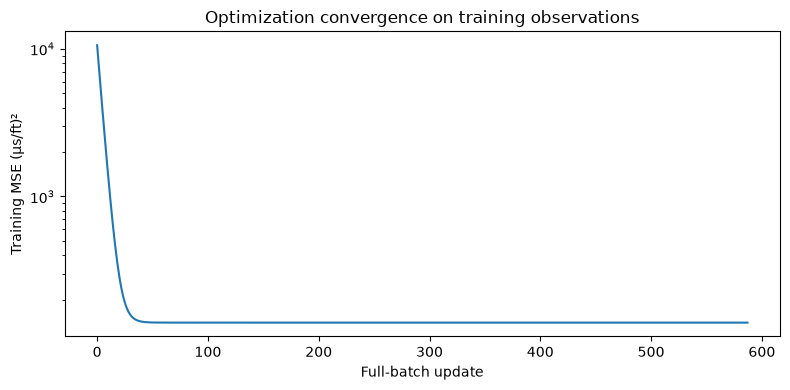

Converged: True Updates: 587
Final gradient norm: 9.999703817710158e-08


In [3]:
fitted = models["lecture_linear"].steps[-1][1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(np.arange(len(fitted.loss_history_)), fitted.loss_history_)
ax.set(xlabel="Full-batch update", ylabel="Training MSE (µs/ft)²",
       title="Optimization convergence on training observations")
fig.tight_layout()
plt.show()
print("Converged:", fitted.converged_, "Updates:", fitted.n_iter_)
print("Final gradient norm:", fitted.gradient_norm_)
assert fitted.converged_, "Investigate convergence before interpreting model comparisons."

## Results, uncertainty, and practical meaning
MAE measures average absolute reconstruction error in µs/ft. RMSE gives larger
errors more weight. The pooled scores below weight each depth observation
equally, so wells with more eligible rows have more influence. The trusted
reference tests optimization agreement; it is not a different scientific model.

In [4]:
labels = {"mean_baseline": "Mean baseline", "lecture_linear": "Batch-gradient linear",
          "least_squares_reference": "Least-squares reference"}
metrics = pd.DataFrame(report["metrics"]).T.rename(index=labels)
display(metrics.rename(columns={"mae": "MAE (µs/ft)", "rmse": "RMSE (µs/ft)"}).round(4))
print("Maximum prediction gap to reference:", report["max_prediction_gap_to_reference"])
assert report["max_prediction_gap_to_reference"] < 1e-4

,MAE (µs/ft),RMSE (µs/ft)
Mean baseline,21.5744,26.4162
Batch-gradient linear,10.5195,14.9360
Least-squares reference,10.5195,14.9360


Maximum prediction gap to reference: 7.845631273539766e-07


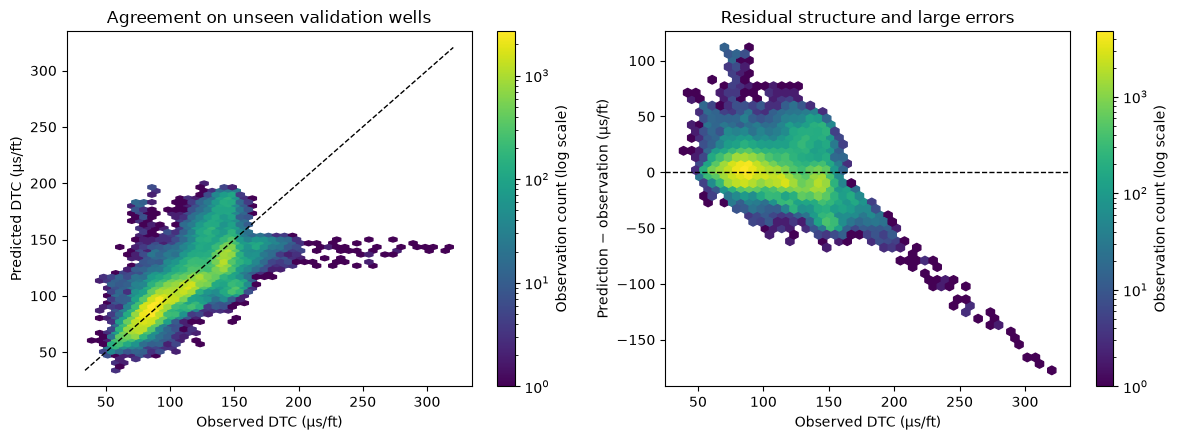

In [5]:
predicted = models["lecture_linear"].predict(validation[features])
observed = validation.DTC.to_numpy()
residual = predicted - observed
# Plot all eligible validation observations using density bins, not selected examples.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
counts = axes[0].hexbin(observed, predicted, gridsize=45, mincnt=1, bins="log")
limits = [min(observed.min(), predicted.min()), max(observed.max(), predicted.max())]
axes[0].plot(limits, limits, "--", color="black", linewidth=1)
axes[0].set(xlabel="Observed DTC (µs/ft)", ylabel="Predicted DTC (µs/ft)",
            title="Agreement on unseen validation wells")
fig.colorbar(counts, ax=axes[0], label="Observation count (log scale)")
counts = axes[1].hexbin(observed, residual, gridsize=45, mincnt=1, bins="log")
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set(xlabel="Observed DTC (µs/ft)", ylabel="Prediction − observation (µs/ft)",
            title="Residual structure and large errors")
fig.colorbar(counts, ax=axes[1], label="Observation count (log scale)")
fig.tight_layout()
plt.show()

## Failure analysis
A single average can hide weak wells. Compare each well against its own
baseline error, then summarize wells equally. Well-to-well variation is not a
confidence interval. With only 20 validation wells, results are sensitive to
which wells are held out. No independent-row confidence interval is justified.

The residual plot shows systematic underprediction at high observed sonic
slowness, especially above roughly 200 µs/ft. This suggests a limitation of the
linear relationship or the represented training data; the plot alone cannot
establish the cause. Investigate these intervals by well and lithology before
considering any exclusion or a more flexible model.


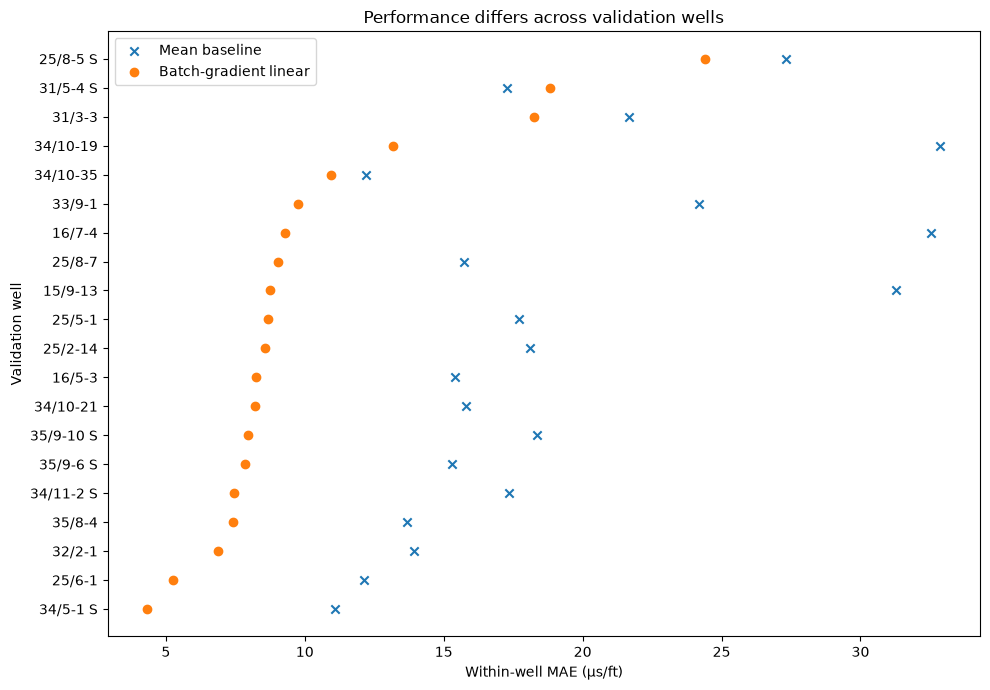

model,Least-squares reference,Batch-gradient linear,Mean baseline
well,,,
34/5-1 S,4.330,4.330,11.078
25/6-1,5.256,5.256,12.125
32/2-1,6.887,6.887,13.919
35/8-4,7.421,7.421,13.670
34/11-2 S,7.450,7.450,17.355
35/9-6 S,7.862,7.862,15.308
35/9-10 S,7.938,7.938,18.362
34/10-21,8.211,8.211,15.801
16/5-3,8.240,8.240,15.408


,Mean well MAE,Median well MAE
model,,
Least-squares reference,10.166,8.621
Batch-gradient linear,10.166,8.621
Mean baseline,19.197,17.311


Linear regression improves MAE over baseline in 19 of 20 validation wells.


In [6]:
well_mae = per_well.pivot(index="well", columns="model", values="mae")
well_mae = well_mae.sort_values("lecture_linear")
fig, ax = plt.subplots(figsize=(10, 7))
positions = np.arange(len(well_mae))
ax.scatter(well_mae.mean_baseline, positions, label="Mean baseline", marker="x")
ax.scatter(well_mae.lecture_linear, positions, label="Batch-gradient linear")
ax.set_yticks(positions, well_mae.index)
ax.set(xlabel="Within-well MAE (µs/ft)", ylabel="Validation well",
       title="Performance differs across validation wells")
ax.legend()
fig.tight_layout()
plt.show()
display(well_mae.rename(columns=labels).round(3))
display(pd.DataFrame({"Mean well MAE": well_mae.mean(),
                      "Median well MAE": well_mae.median()}).rename(index=labels).round(3))
improved = int((well_mae.lecture_linear < well_mae.mean_baseline).sum())
print(f"Linear regression improves MAE over baseline in {improved} of {len(well_mae)} validation wells.")

## Conclusion and production decision
The initial development run gives pooled MAE about **10.52 µs/ft**, compared
with **21.57 µs/ft** for the training-mean baseline. Matching the reference
supports implementation correctness, while the per-well diagnostics reveal
uneven generalization. This is a useful first benchmark, not a deployment decision.

The next comparison is a shallow regression tree to test whether nonlinear
relationships improve reconstruction. Further work includes lithology-specific
error analysis, repeated development well splits and sampling sensitivity.
PCA remains a supporting analysis, not a required preprocessing step for these
three predictors. Freeze model choices before evaluating the reserved wells.
Observed-target reconstruction does not establish accuracy where DTC is truly
missing, nor demonstrate oil presence or operational savings.

## Definition of done
- [x] Scientific question, source and target units stated.
- [x] Whole-well boundaries and training-only preprocessing applied.
- [x] Tested package implementation, baseline and trusted reference compared.
- [x] Convergence, residual and well-level diagnostics reported.
- [ ] Repeated-split uncertainty, rock-type diagnostics and final-model comparison.
- [ ] Final-test evaluation after model selection is frozen.

Run from top to bottom using the project environment. Full-data execution
requires the ignored archive; continuous integration validates notebook
structure without downloading field data. Local execution supplies the
full-data integration check. Generated experiment artifacts remain ignored.

The model improves MAE in 19 of 20 validation wells. Well 31/5-4 S is the
exception: its linear-model MAE is about 18.84 µs/ft versus about 17.27 for the
baseline. Well 25/8-5 S has the largest linear-model MAE (24.41 µs/ft), even
though that is an improvement over its baseline. Improvement and adequacy are
different questions; no domain acceptance threshold has yet been established.
